In [ ]:
# ==========================================
# CELL 1: Imports & Synthetic Data Generator
# ==========================================
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

def generate_synthetic_market(n_assets=5, n_steps=1500, dt=1/252, seed=42):
    """
    Generates synthetic daily returns using Geometric Brownian Motion.
    Simulates different asset profiles (e.g., strong positive drift, strong negative drift, high vol).
    """
    np.random.seed(seed)

    mus = np.array([0.25, 0.12, 0.02, -0.10, -0.20])
    sigmas = np.array([0.20, 0.15, 0.10, 0.25, 0.30]) 
    
    returns = np.zeros((n_steps, n_assets))
    
    for i in range(n_assets):
        drift = (mus[i] - 0.5 * sigmas[i]**2) * dt
        shock = sigmas[i] * np.sqrt(dt) * np.random.randn(n_steps)
        returns[:, i] = drift + shock
        
    prices = 100 * np.exp(np.cumsum(returns, axis=0))
    return returns, prices, mus, sigmas

# Generate 1500 time steps of synthetic market data
returns_data, prices_data, asset_mus, asset_sigmas = generate_synthetic_market()

print("Synthetic Assets Created:")
for idx, (m, s) in enumerate(zip(asset_mus, asset_sigmas)):
    print(f" Asset {idx}: Annual Drift = {m*100:+.1f}%, Volatility = {s*100:.1f}%")

Synthetic Assets Created:
 Asset 0: Annual Drift = +25.0%, Volatility = 20.0%
 Asset 1: Annual Drift = +12.0%, Volatility = 15.0%
 Asset 2: Annual Drift = +2.0%, Volatility = 10.0%
 Asset 3: Annual Drift = -10.0%, Volatility = 25.0%
 Asset 4: Annual Drift = -20.0%, Volatility = 30.0%


In [8]:
# ==========================================
# CELL 2: Custom Gymnasium Environment
# ==========================================
class SyntheticPortfolioEnv(gym.Env):
    """
    Custom Gymnasium Environment for Dynamic Asset Allocation.
    """
    def __init__(self, returns_matrix, window_size=20, transaction_cost=0.0005):
        super(SyntheticPortfolioEnv, self).__init__()
        
        self.returns = returns_matrix # Shape: (n_steps, n_assets)
        self.n_steps, self.n_assets = returns_matrix.shape
        self.window_size = window_size
        self.tc = transaction_cost # 0.05% fee per rebalance turnover
        
        # Action Space: Unnormalized weight preference for each asset (0.0 to 1.0)
        self.action_space = spaces.Box(
            low=0.0, high=1.0, shape=(self.n_assets,), dtype=np.float32
        )
        
        # Observation Space: Rolling Means (5) + Rolling Std Devs (5) + Current Portfolio Weights (5)
        obs_dim = self.n_assets * 3
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32
        )
        
        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = self.window_size
        # Start equal-weighted
        self.current_weights = np.ones(self.n_assets, dtype=np.float32) / self.n_assets
        self.portfolio_value = 1.0
        
        return self._get_observation(), {}

    def _get_observation(self):
        # Extract rolling statistical metrics over window_size
        window = self.returns[self.current_step - self.window_size : self.current_step]
        rolling_mean = np.mean(window, axis=0)
        rolling_std = np.std(window, axis=0) + 1e-8 # Add epsilon to prevent div zero
        
        # Combine statistics and current weights into single state vector
        obs = np.concatenate([rolling_mean, rolling_std, self.current_weights]).astype(np.float32)
        return obs

    def step(self, action):
        # Normalize actions using Softmax / L1-norm so weights sum exactly to 1.0
        action = np.clip(action, 1e-5, 1.0)
        target_weights = action / np.sum(action)
        
        # Calculate Turnover Penalty
        turnover = np.sum(np.abs(target_weights - self.current_weights))
        rebalance_cost = turnover * self.tc
        
        # Realize Step Returns for time 't'
        step_returns = self.returns[self.current_step]
        net_portfolio_return = np.dot(target_weights, step_returns) - rebalance_cost
        
        # Update Portfolio Value
        self.portfolio_value *= (1.0 + net_portfolio_return)
        
        # Update portfolio weights drift due to market movement
        self.current_weights = target_weights * (1.0 + step_returns)
        self.current_weights /= np.sum(self.current_weights)
        
        self.current_step += 1
        terminated = self.current_step >= self.n_steps - 1
        truncated = False
        
        # Reward Function: Net return minus variance penalty (Risk-Adjusted Return)
        variance_penalty = 0.5 * np.var(step_returns * target_weights)
        reward = float(net_portfolio_return - variance_penalty)
        
        info = {
            "portfolio_value": self.portfolio_value,
            "step_return": net_portfolio_return,
            "weights": target_weights
        }
        
        return self._get_observation(), reward, terminated, truncated, info

In [9]:
# ==========================================
# CELL 3: Train PPO Agent & Evaluate Baseline
# ==========================================
# Train/Test Split (First 1000 steps for training, last 500 for out-of-sample testing)
train_returns = returns_data[:1000]
test_returns = returns_data[1000:]

train_env = SyntheticPortfolioEnv(train_returns)
test_env = SyntheticPortfolioEnv(test_returns)

# Instantiate Stable-Baselines3 PPO Agent
model = PPO("MlpPolicy", train_env, verbose=0, learning_rate=0.0003)

print("Training RL Agent...")
model.learn(total_timesteps=100000)
print("Training Complete!")

Training RL Agent...
Training Complete!


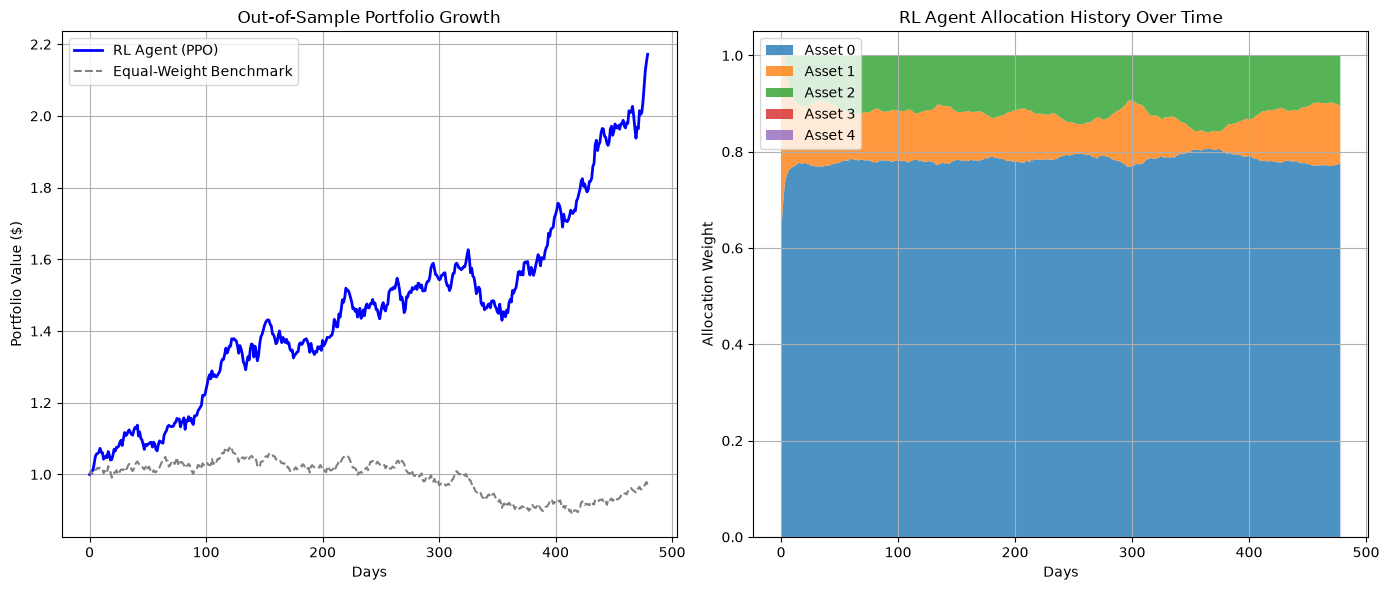

In [10]:
# ==========================================
# CELL 4: Out-of-Sample Backtest & Visualization
# ==========================================
obs, _ = test_env.reset()
done = False

rl_values = [1.0]
rl_weights_history = []

# 1. Run RL Agent Backtest
while not done:
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = test_env.step(action)
    done = terminated or truncated
    
    rl_values.append(info["portfolio_value"])
    rl_weights_history.append(info["weights"])

# 2. Run Equal-Weight Benchmark (20% in each asset)
benchmark_values = [1.0]
bench_value = 1.0
tc = 0.0005
equal_weights = np.ones(5) / 5.0

for r in test_returns[20:]: # Match step window offset
    step_ret = np.dot(equal_weights, r)
    bench_value *= (1.0 + step_ret)
    benchmark_values.append(bench_value)

# Plot Results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(rl_values, label="RL Agent (PPO)", color="blue", linewidth=2)
plt.plot(benchmark_values, label="Equal-Weight Benchmark", color="gray", linestyle="--")
plt.title("Out-of-Sample Portfolio Growth")
plt.xlabel("Days")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
weights_df = pd.DataFrame(rl_weights_history, columns=[f"Asset {i}" for i in range(5)])
plt.stackplot(range(len(weights_df)), weights_df.T, labels=weights_df.columns, alpha=0.8)
plt.title("RL Agent Allocation History Over Time")
plt.xlabel("Days")
plt.ylabel("Allocation Weight")
plt.legend(loc="upper left")
plt.grid(True)

plt.tight_layout()
plt.show()